In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import sys
from ast import literal_eval
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import regionmask
import seaborn as sns
import windpowerlib.power_curves as pc
import xarray as xr
from windpowerlib import wind_turbine as wt
from windpowerlib.data import store_turbine_data_from_oedb

sns.set_style("whitegrid", {"grid.color": ".93"})

sys.path.append("../..")

from src.conversion_energy.wind import (
    compute_power_law_exponent,
    compute_smooth_power_curve,
    compute_wind_power,
    extrapolate_wind_speed,
)
from src.data_processing.load_data import ClimateModelData
from src.utils.utils_xarray import sel_extent
from src.conversion_energy.aggregate_data import aggregate_data_per_country, create_country_offshore_mask

In [3]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"

path_energy_ch = path_data_processed / "energy" / "ch"
path_energy_europe = path_data_processed / "energy" / "europe"

path_figs = Path(paths["path_figs"])

In [4]:
europe_turbines = ["E-126/7580", "SWT120/3600", "SWT142/3150"]
ch_turbines = ["E-82/2300", "E-92/2350", "V90/2000", "V112/3300"]
ch_hub_heights = {"E-82/2300": 98, "E-92/2350": 98, "V90/2000": 95, "V112/3300": 94}
df_turbine = store_turbine_data_from_oedb()

In [5]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}
extent_ch = {"lat_min": 45.8, "lat_max": 47.9, "lon_min": 5.9, "lon_max": 10.5}

In [6]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

# Switzerland

# Europe

In [7]:
selected_turbine = europe_turbines[0]

In [8]:
path_wind_power = (
    path_energy_europe
    / "wind_power"
    / f"{climate_model_chain}_{climate_scenario}"
    / f"wind_power_{climate_model_chain}_{climate_scenario}_{selected_turbine.replace('/', '_')}.zarr"
)

path_wind_power_agg = (
    path_energy_europe
    / "wind_power"
    / f"{climate_model_chain}_{climate_scenario}"
    / f"wind_power_agg_{climate_model_chain}_{climate_scenario}_{selected_turbine.replace('/', '_')}.nc"
)
path_wind_power_offshore = (
    path_energy_europe
    / "wind_power"
    / f"{climate_model_chain}_{climate_scenario}"
    / f"wind_power_offshore_{climate_model_chain}_{climate_scenario}_{selected_turbine.replace('/', '_')}.nc"
)
ds_wind_power_agg = xr.open_dataset(path_wind_power_agg)
ds_wind_power_offshore = xr.open_dataset(path_wind_power_offshore)
ds_wind_power = xr.open_zarr(path_wind_power, chunks="auto")

In [19]:
mask, countries = create_country_offshore_mask(ds_wind_power, path_data_processed / "maps" / "eez_v12" / "eez_v12.shp")
mask = mask.fillna(-1)

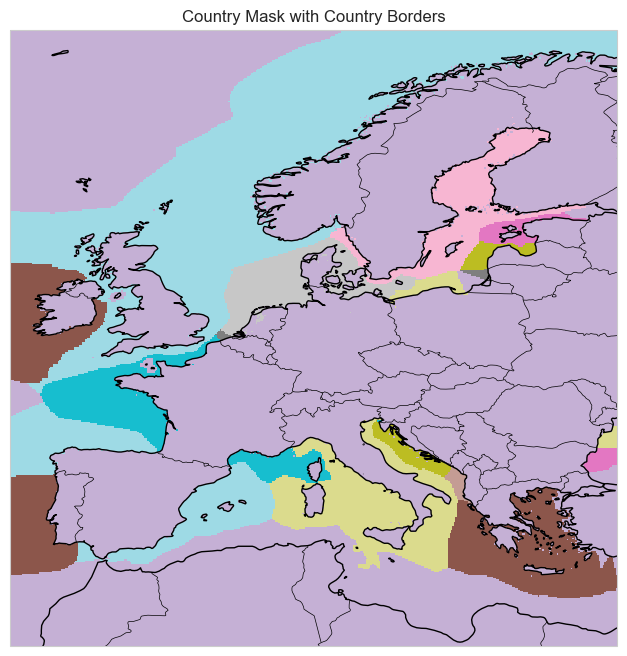

In [20]:
fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={"projection": ccrs.PlateCarree()})
mask.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="tab20", add_colorbar=False)
ax.coastlines()
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.set_title("Country Mask with Country Borders")
plt.show()

In [21]:
ds_test = aggregate_data_per_country(
        ds_wind_power.isel(time=slice(None, 2920)),
        method="median_and_better",
        offshore=True,
        path_eez_file=path_data_processed / "maps" / "eez_v12" / "eez_v12.shp",
    )

/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/xarray/core/dataset.py:5195: PerformanceWarning: Reshaping is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array.reshape(shape)

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array.reshape(shape)Explicitly passing ``limit`` to ``reshape`` will also silence this warning
    >>> array.reshape(shape, limit='128 MiB')
  stacked_var = exp_var.stack(**{new_dim: dims})


In [16]:
ds_test

<xarray.Dataset> Size: 539kB
Dimensions:     (time: 2920, country: 22)
Coordinates:
  * time        (time) datetime64[ns] 23kB 1991-01-01 ... 1991-12-31T21:00:00
  * country     (country) <U14 1kB 'Greece' 'Montenegro' ... 'Norway' 'Spain'
Data variables:
    E-126_7580  (time, country) float64 514kB dask.array<chunksize=(2920, 22), meta=np.ndarray>

[]

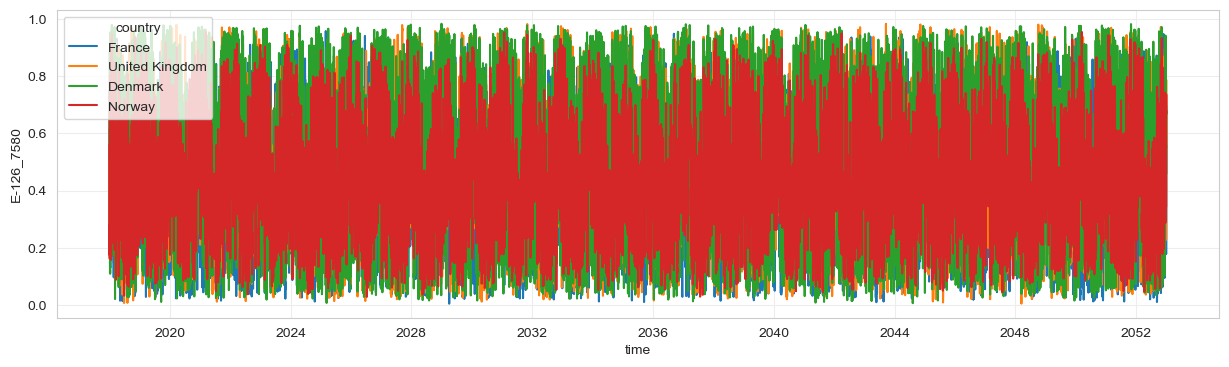

In [9]:
ds_wind_power_offshore[selected_turbine.replace("/", "_")].sel(
    time=slice("2018", "2052"),
    country=["France", "United Kingdom", "Denmark", "Norway"],
).resample(time="1D").mean(dim="time").plot.line(x="time", figsize=(15, 4))
plt.plot()

In [10]:
reference_period = slice("1991", "2020")
future_period = slice("2021", "2050")

In [11]:
# Calculate the mean values for the future period
mean_future = (ds_wind_power[selected_turbine.replace("/", "_")]).sel(time=future_period).mean(dim="time")

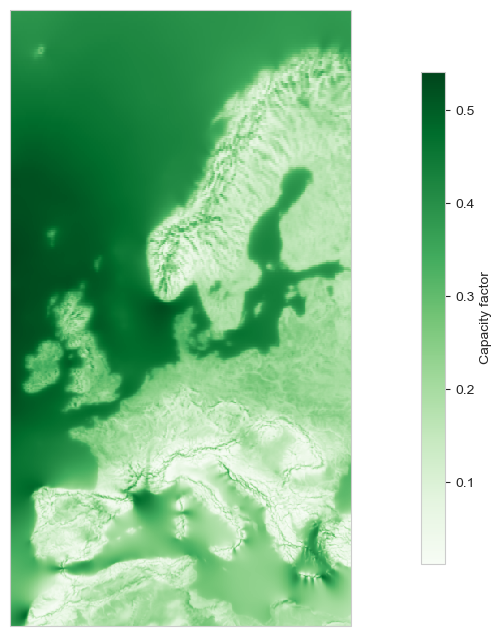

In [12]:
proj = ccrs.Mercator(central_longitude=10.0, min_latitude=30.0, max_latitude=75.0)
fig, axes = plt.subplots(figsize=(18, 8), subplot_kw={"projection": proj})
mean_future.plot(
    ax=axes,
    cmap="Greens",
    transform=ccrs.PlateCarree(),
    cbar_kwargs={
        "label": "Capacity factor",
        "shrink": 0.8,
        "orientation": "vertical",
        "pad": 0.05,
        "aspect": 20,
    },
)
plt.show()